# BrushCue Example: Shadows & Highlights

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/shadows_highlights.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/shadows-highlights

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


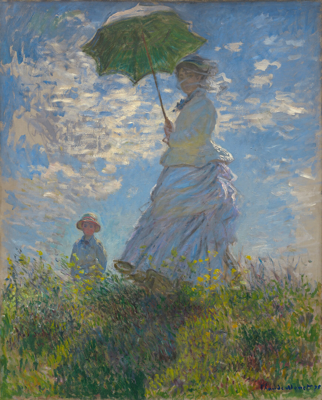

In [1]:
import io
from PIL import Image

import brushcue as bc

shadows = 0.5
highlights = -0.35
strength = 1.0
input_image = bc.Composition.monet_women_with_parasol()
graph = input_image.color_transformer_shader(
    "// Preserve the original exactly when the correction is disabled.\nif (strength <= 0.0 || (shadows == 0.0 && highlights == 0.0)) { return input; }\nlet l = clamp(input.r, 0.0, 1.0);\nlet shadow_weight = 1.0 - smoothstep(0.05, 0.5, l);\nlet highlight_weight = smoothstep(0.5, 0.95, l);\n// Bounded shifts in log-odds space keep the curve monotonic across all slider values.\n// Pure black, middle gray in OkLab, and pure white remain anchored.\nlet shift = (shadows * shadow_weight + highlights * highlight_weight) * strength;\nlet corrected = l / max(l + (1.0 - l) * exp(-shift), 0.0001);\nreturn vec4f(corrected, input.g, input.b, input.a);",
    "",
    bc.ColorRepresentation.oklab_a(),
    bc.ColorRepresentation.oklab_a(),
    bc.Dictionary.create()
    .add("shadows", shadows)
    .add("highlights", highlights)
    .add("strength", strength),
)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
